# 02 · Analysis: need, country types, allocation, confidence

Input: the prepared data from `01_data_preparation.ipynb`.

| Board question | Data science job | Method |
|---|---|---|
| **Need:** who needs support most, and what is "need"? | Find the main direction along which countries differ and turn it into a score | PCA, first component = *need index* |
| **Types:** are there distinct types of countries? | Group countries without labels | k-means on principal components, checked with Ward and GMM |
| **Allocation:** ≤ 15 countries, one programme each | Rank within the high-need type, then match each country's profile to a programme | Need index + transparent profile scores (A/B/C) |
| **Confidence:** how robust is it? | Re-run the decision under plausible alternative choices | Bootstrap, alternative k / algorithms, 1,000 weighting scenarios |


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_theme(style="whitegrid")
Path("results").mkdir(exist_ok=True)
SEED = 42

clean = pd.read_csv("data/country_data_clean.csv", index_col="country")
Z = pd.read_csv("data/country_features_model.csv", index_col="country")
INDICATORS = list(Z.columns)
print(Z.shape)

(167, 9)


## 1. Need: what does "need" mean in the data?

PCA finds the directions along which countries differ most. If one direction dominates and combines the health and income indicators, that direction is a data-driven definition of *need*.

,explained,cumulative
PC1,0.532,0.532
PC2,0.163,0.695
PC3,0.146,0.841
PC4,0.070,0.910
PC5,0.043,0.953


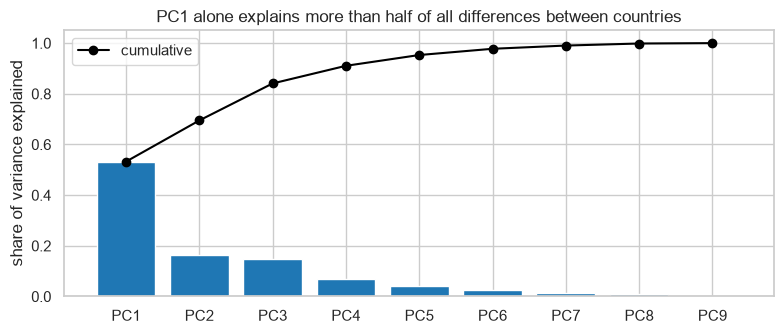

In [2]:
pca = PCA(random_state=SEED).fit(Z)
evr = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(len(INDICATORS))])

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(evr.index, evr.values, color="tab:blue")
ax.plot(evr.index, evr.cumsum().values, marker="o", color="black", label="cumulative")
ax.set_ylabel("share of variance explained")
ax.legend()
ax.set_title("PC1 alone explains more than half of all differences between countries")
plt.tight_layout()
evr.round(3).to_frame("explained").assign(cumulative=evr.cumsum().round(3)).head(5)

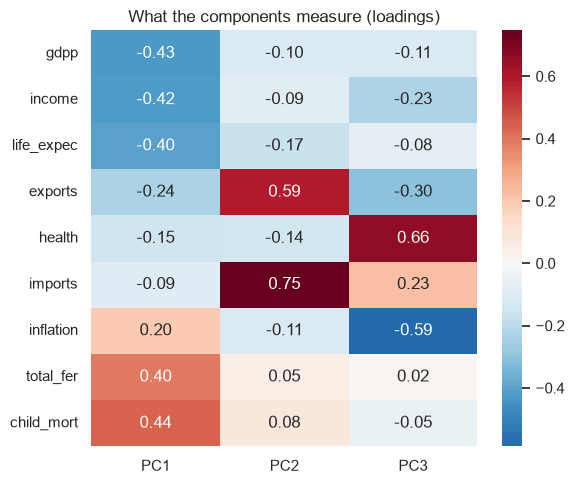

In [3]:
loadings = pd.DataFrame(pca.components_[:3].T, index=INDICATORS, columns=["PC1", "PC2", "PC3"])
# orient PC1 so that a higher value means more need (child mortality loads positively)
sign = np.sign(loadings.loc["child_mort", "PC1"])
loadings["PC1"] *= sign

plt.figure(figsize=(6, 5))
sns.heatmap(loadings.sort_values("PC1"), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("What the components measure (loadings)")
plt.tight_layout()

**Interpretation**
* **PC1 = need axis (53 % of variance).** High child mortality and fertility on one side, high income, GDP and life expectancy on the other. Trade, health spending and inflation play a much smaller role. This is our **need index**.
* **PC2 = trade openness** (exports and imports).
* **PC3 = health spending vs. inflation.**

The first four components explain about 91 % of the variance, so we cluster on PC1 to PC4. This also removes the double counting of correlated indicators found in notebook 01.

In [4]:
scores = pd.DataFrame(pca.transform(Z)[:, :4], index=Z.index, columns=["PC1", "PC2", "PC3", "PC4"])
scores["PC1"] *= sign
P = scores.values

need_raw = scores["PC1"]
need_index = 100 * (need_raw - need_raw.min()) / (need_raw.max() - need_raw.min())
need_index.sort_values(ascending=False).head(20).round(1).to_frame("need index (0-100)")

,need index (0-100)
country,
Central African Republic,100.0
"Congo, Dem. Rep.",99.0
Niger,98.1
Haiti,97.2
Burundi,96.6
Sierra Leone,94.3
Malawi,94.3
Mozambique,93.2
Guinea,92.0


## 2. Types: how many groups, and what are they?

No single statistic decides k. We combine three arguments: the elbow, the silhouette score and, most importantly, **whether the groups are interpretable and stable**.

k,2,3,4,5,6,7,8
silhouette,0.355,0.276,0.279,0.299,0.293,0.29,0.307


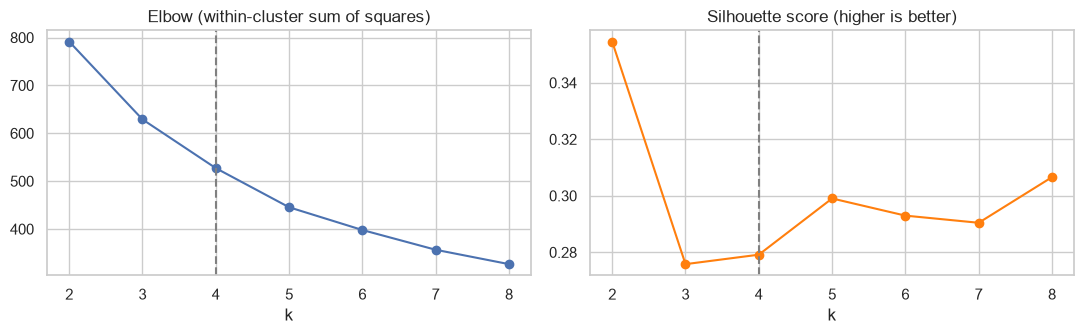

In [5]:
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=50, random_state=SEED).fit(P)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(P, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(list(ks), inertia, marker="o"); axes[0].set_title("Elbow (within-cluster sum of squares)"); axes[0].set_xlabel("k")
axes[1].plot(list(ks), sil, marker="o", color="tab:orange"); axes[1].set_title("Silhouette score (higher is better)"); axes[1].set_xlabel("k")
for ax in axes: ax.axvline(4, ls="--", color="grey")
plt.tight_layout()
pd.DataFrame({"k": list(ks), "silhouette": np.round(sil, 3)}).set_index("k").T

* **k = 2** has the best silhouette, but it only splits *rich* from *poor*. That is the GDP ranking Dr. Okafor explicitly does not want.
* **k = 3 and k = 4** score the same; k = 4 separates the very open trade economies (Singapore, Luxembourg, Malta, ...) from other advanced economies, which makes the groups easier to explain.
* Above k = 4 the gain is small and the groups get harder to name.

**We choose k = 4.** The high-need group is the same 44 countries for k = 3 and k = 4 (checked below), so the shortlist does not depend on this choice.

In [6]:
K = 4
km = KMeans(K, n_init=50, random_state=SEED).fit(P)
labels = pd.Series(km.labels_, index=Z.index)

# name clusters by their profile so the names stay correct if cluster numbers change
med = clean[INDICATORS].groupby(labels).median()
names = {}
names[med["child_mort"].idxmax()] = "High need"
rest = med.drop(index=list(names))
names[rest["exports"].idxmax()] = "Open trade economies"
rest = rest.drop(index=rest["exports"].idxmax())
names[rest["gdpp"].idxmax()] = "Advanced economies"
names[rest.drop(index=rest["gdpp"].idxmax()).index[0]] = "Emerging economies"
cluster = labels.map(names)
ORDER = ["High need", "Emerging economies", "Open trade economies", "Advanced economies"]
PALETTE = dict(zip(ORDER, ["#d62728", "#ff7f0e", "#1f77b4", "#2ca02c"]))
cluster.value_counts().reindex(ORDER).to_frame("countries")

,countries
High need,44
Emerging economies,63
Open trade economies,25
Advanced economies,35


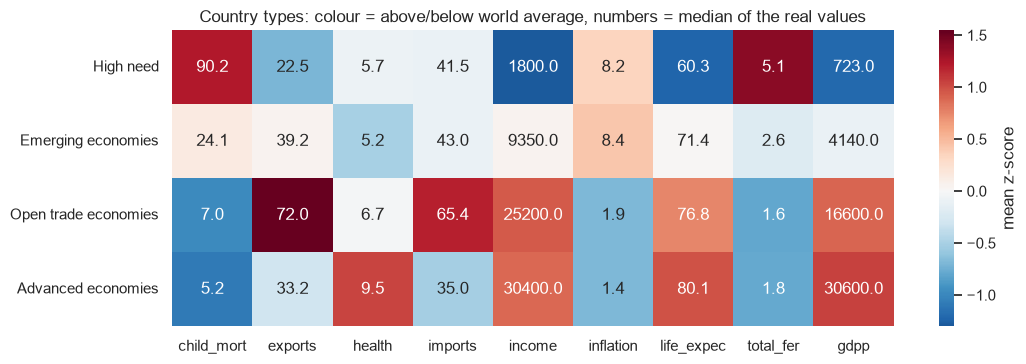

In [7]:
profile = clean[INDICATORS].groupby(cluster).median().reindex(ORDER)
profile_z = Z.groupby(cluster).mean().reindex(ORDER)

plt.figure(figsize=(11, 3.8))
sns.heatmap(profile_z, annot=profile.round(1), fmt="", cmap="RdBu_r", center=0, cbar_kws={"label": "mean z-score"})
plt.title("Country types: colour = above/below world average, numbers = median of the real values")
plt.ylabel("")
plt.tight_layout()

In [8]:
for name in ORDER:
    members = sorted(cluster[cluster == name].index)
    print(f"{name} ({len(members)}): {', '.join(members)}\n")

High need (44): Afghanistan, Angola, Benin, Burkina Faso, Burundi, Cameroon, Central African Republic, Chad, Comoros, Congo, Dem. Rep., Cote d'Ivoire, Eritrea, Gambia, Ghana, Guinea, Guinea-Bissau, Haiti, Kenya, Kiribati, Lao, Lesotho, Liberia, Madagascar, Malawi, Mali, Mauritania, Micronesia, Fed. Sts., Mozambique, Nepal, Niger, Nigeria, Pakistan, Rwanda, Senegal, Sierra Leone, Solomon Islands, Sudan, Tajikistan, Tanzania, Timor-Leste, Togo, Uganda, Yemen, Zambia

Emerging economies (63): Albania, Algeria, Argentina, Armenia, Azerbaijan, Bangladesh, Belarus, Belize, Bhutan, Bolivia, Botswana, Brunei, Cambodia, Cape Verde, China, Congo, Rep., Dominican Republic, Ecuador, Egypt, El Salvador, Equatorial Guinea, Fiji, Gabon, Georgia, Grenada, Guatemala, Guyana, India, Indonesia, Iran, Iraq, Jamaica, Jordan, Kazakhstan, Kuwait, Kyrgyz Republic, Libya, Macedonia, FYR, Moldova, Mongolia, Morocco, Myanmar, Namibia, Oman, Paraguay, Peru, Philippines, Romania, Russia, Samoa, Saudi Arabia, South

| Type | What characterises it |
|---|---|
| **High need** | Child mortality ~90 per 1,000, ~5 children per woman, life expectancy ~60 years, GDP per capita ~700 USD. Mostly sub-Saharan Africa plus Afghanistan, Haiti, Pakistan, Yemen and some Pacific islands. |
| **Emerging economies** | Middle income, child mortality ~24, life expectancy ~71. Largest group, including India, China, Indonesia, Egypt and South Africa. |
| **Open trade economies** | Exports and imports above 70 % of GDP, mostly wealthy small states and trade hubs. |
| **Advanced economies** | Highest income, lowest mortality, highest health spending. Also contains a few upper-middle-income countries with low trade openness (e.g. Brazil, Turkey, Colombia). |

Only the **High need** type is relevant for the foundation's first wave.

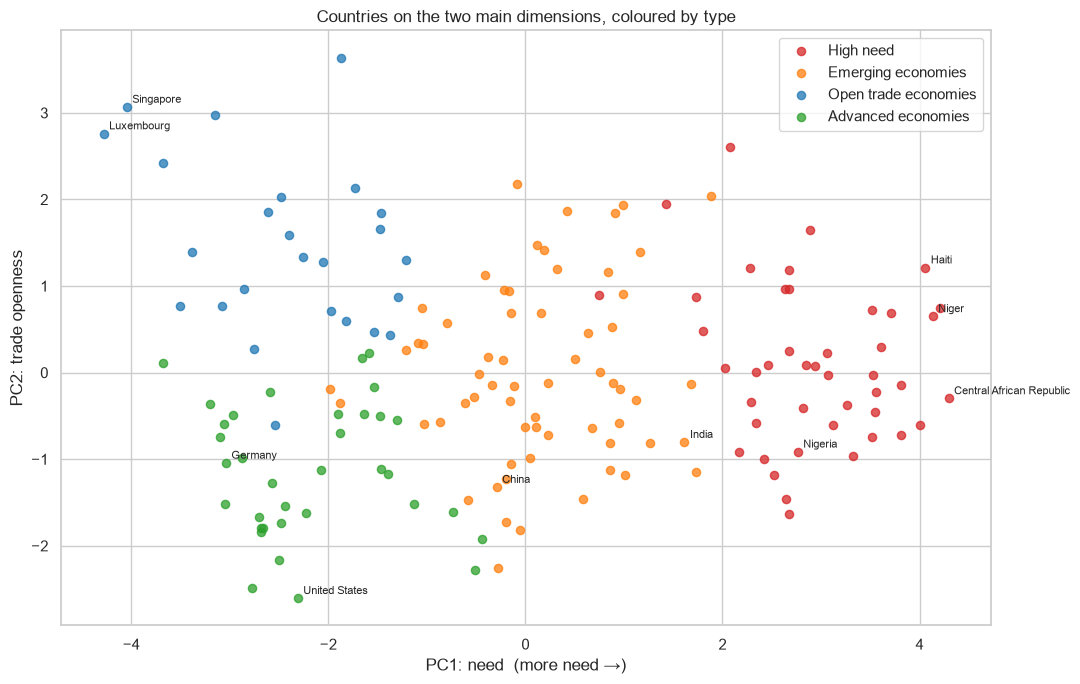

In [9]:
fig, ax = plt.subplots(figsize=(11, 7))
for name in ORDER:
    m = cluster == name
    ax.scatter(scores.loc[m, "PC1"], scores.loc[m, "PC2"], s=35, alpha=0.75, color=PALETTE[name], label=name)
for c in ["Niger", "Central African Republic", "Haiti", "India", "China", "Germany", "Singapore", "Luxembourg", "Nigeria", "United States"]:
    ax.annotate(c, (scores.loc[c, "PC1"], scores.loc[c, "PC2"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("PC1: need  (more need →)")
ax.set_ylabel("PC2: trade openness")
ax.set_title("Countries on the two main dimensions, coloured by type")
ax.legend()
plt.tight_layout()

### 2.1 Are the types stable?

Three checks:
1. **Other k:** does the high-need group change for k = 3, 5, 6?
2. **Other algorithms:** do hierarchical clustering (Ward) and Gaussian mixtures find the same high-need group?
3. **Bootstrap:** refit k-means on 300 resampled datasets and count how often each country falls into the high-need group.

In [10]:
hn = cluster == "High need"

def high_need_members(lbl):
    lbl = pd.Series(lbl, index=Z.index)
    g = clean.groupby(lbl)["child_mort"].median().idxmax()
    return lbl == g

rows = []
for k in [3, 4, 5, 6]:
    m = high_need_members(KMeans(k, n_init=50, random_state=SEED).fit_predict(P))
    rows.append({"variant": f"k-means k={k}", "size": m.sum(), "overlap with k=4 group": (m & hn).sum()})
for name, lbl in [("Ward k=4", AgglomerativeClustering(4, linkage="ward").fit_predict(P)),
                  ("GMM k=4", GaussianMixture(4, n_init=10, random_state=SEED).fit(P).predict(P))]:
    m = high_need_members(lbl)
    rows.append({"variant": name, "size": m.sum(), "overlap with k=4 group": (m & hn).sum()})
pd.DataFrame(rows).set_index("variant")

,size,overlap with k=4 group
variant,,
k-means k=3,44,44
k-means k=4,44,44
k-means k=5,39,39
k-means k=6,11,11
Ward k=4,37,37
GMM k=4,36,34


In [11]:
rng = np.random.default_rng(SEED)
B = 300
in_hn = pd.Series(0.0, index=Z.index)
for b in range(B):
    idx = rng.choice(len(P), len(P), replace=True)
    kb = KMeans(K, n_init=10, random_state=b).fit(P[idx])
    lbl = kb.predict(P)
    in_hn += high_need_members(lbl).astype(float)
cluster_stability = (in_hn / B).rename("share of bootstrap runs in High need")

borderline = cluster_stability[(cluster_stability > 0.05) & (cluster_stability < 0.95)].sort_values()
print(f"Countries that are stably in the High need group (>=95% of runs): {(cluster_stability >= 0.95).sum()}")
borderline.round(2).to_frame()

Countries that are stably in the High need group (>=95% of runs): 34


,share of bootstrap runs in High need
country,
Botswana,0.05
Guatemala,0.06
Philippines,0.06
Samoa,0.06
Tonga,0.09
South Africa,0.10
Namibia,0.14
Vanuatu,0.15
"Congo, Rep.",0.18


* The high-need group is **identical for k = 3 and k = 4**. For k = 5 it shrinks to a core of 39, for k = 6 to 11: more groups split the poorest countries further, but never mix them with richer ones.
* **Ward and GMM** find a smaller core (37 and 36 countries) that lies (almost) entirely inside our group. The disagreement is only about *where the group ends*, not about who is in its centre.
* In the bootstrap, 34 countries are in the group in ≥ 95 % of runs. The countries that switch (table) sit at the *upper edge* of the group (e.g. India, Bangladesh, Pakistan, Yemen), far away from the shortlist. **All 15 shortlisted countries are in the high-need group in ≥ 97 % of runs.**

Clusters are a modelling choice, not natural facts. What matters for the decision is that the *centre* of the high-need group is the same under every reasonable choice.

## 3. Allocation: which ≤ 15 countries?

Rule: **rank all countries by need, but only consider countries in the High need type.** Then test how sensitive the top 15 are to the weighting of the indicators.

### 3.1 Sensitivity of the ranking

The need index (PC1) implicitly weights the indicators by how strongly they correlate. A critic could argue for different weights ("child mortality matters more than income"). We therefore simulate **1,000 alternative need scores**: random weights over the five core need indicators (child mortality, life expectancy, fertility, income, GDP per capita) plus small noise to mimic measurement error, and count how often each country ends up in the top 15.

In [12]:
core = {"child_mort": 1, "life_expec": -1, "total_fer": 1, "income": -1, "gdpp": -1}
N_SIM = 1000
hits = pd.Series(0, index=Z.index)
for s in range(N_SIM):
    w = rng.dirichlet(np.ones(len(core)))
    score = sum(wi * d * Z[c] for wi, (c, d) in zip(w, core.items()))
    score = score + rng.normal(0, 0.1, len(score))
    hits[score[hn].nlargest(15).index] += 1
top15_share = (hits / N_SIM).rename("top15_share")

# leave-one-indicator-out: does the top 15 survive if a single indicator is dropped?
loo = pd.Series(0, index=Z.index)
for drop in INDICATORS:
    Zd = Z.drop(columns=drop)
    p = PCA(1).fit(Zd)
    s = pd.Series(p.transform(Zd)[:, 0], index=Z.index)
    s *= np.sign(np.corrcoef(s, Z["child_mort"])[0, 1])
    loo[s[hn].nlargest(15).index] += 1
loo_share = (loo / len(INDICATORS)).rename("loo_share")

In [13]:
ranking = pd.DataFrame({
    "type": cluster,
    "need_index": need_index.round(1),
    "need_rank": need_index[hn].rank(ascending=False),
    "top15_share": top15_share,
    "loo_share": loo_share.round(2),
    "cluster_stability": cluster_stability.round(2),
})[hn].sort_values(["top15_share", "need_index"], ascending=False)
ranking.head(22)

,type,need_index,need_rank,top15_share,loo_share,cluster_stability
country,,,,,,
"Congo, Dem. Rep.",High need,99.0,2.0,0.993,1.00,1.00
Niger,High need,98.1,3.0,0.985,1.00,1.00
Central African Republic,High need,100.0,1.0,0.982,1.00,1.00
Burundi,High need,96.6,5.0,0.974,1.00,1.00
Mozambique,High need,93.2,8.0,0.968,1.00,1.00
Sierra Leone,High need,94.3,6.0,0.952,1.00,1.00
Malawi,High need,94.3,7.0,0.879,1.00,1.00
Chad,High need,91.0,13.0,0.818,0.89,1.00
Burkina Faso,High need,91.3,11.0,0.796,1.00,1.00


### 3.2 Shortlist rule

* **Shortlist** = the 15 high-need countries that land in the top 15 most often across the 1,000 scenarios (ties broken by need index).
* **Selection confidence:** *High* if selected in ≥ 85 % of scenarios, *Medium* 60 to 85 %, *Low* < 60 %.
* The next five countries are the **reserve list**: they are the first to move in if a shortlisted country is not feasible (e.g. security, no local partner).

In [14]:
ranking["selected"] = False
ranking.iloc[:15, ranking.columns.get_loc("selected")] = True

def sel_conf(x):
    return "High" if x >= 0.85 else ("Medium" if x >= 0.60 else "Low")
ranking["selection_confidence"] = ranking["top15_share"].map(sel_conf)
shortlist = ranking[ranking["selected"]].copy()
reserve = ranking[~ranking["selected"]].head(5).copy()
print("Reserve list:", ", ".join(f"{c} ({v:.0%})" for c, v in reserve["top15_share"].items()))

Reserve list: Guinea (58%), Togo (38%), Lesotho (28%), Zambia (21%), Gambia (17%)


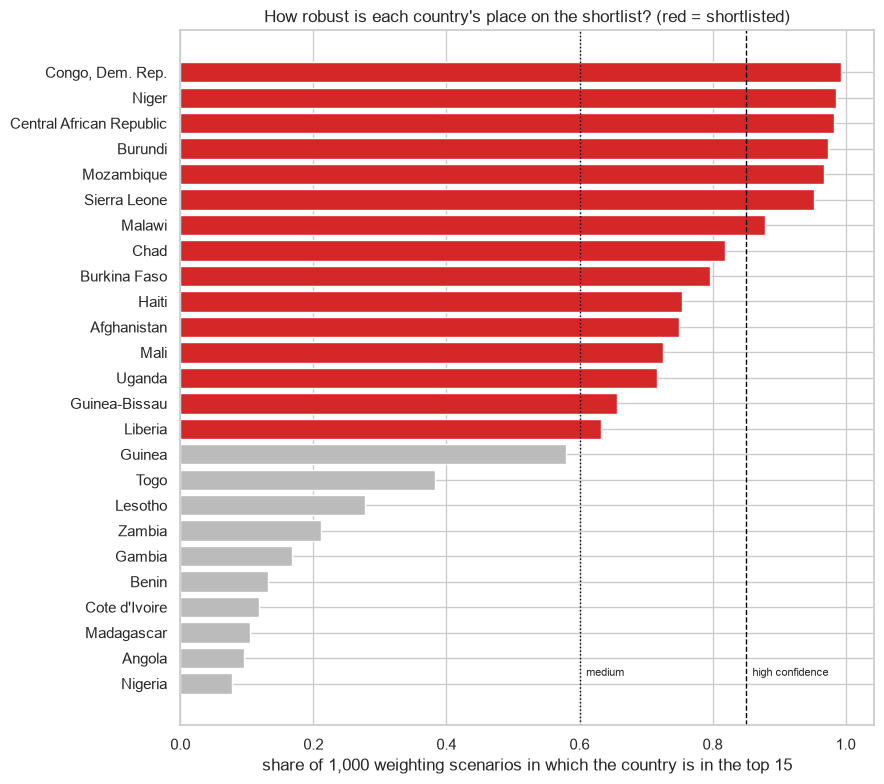

In [15]:
top = ranking.head(25).iloc[::-1]
colors = ["#d62728" if s else "#bbbbbb" for s in top["selected"]]
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top.index, top["top15_share"], color=colors)
ax.axvline(0.85, ls="--", color="black", lw=1); ax.text(0.86, 0.3, "high confidence", fontsize=8)
ax.axvline(0.60, ls=":", color="black", lw=1); ax.text(0.61, 0.3, "medium", fontsize=8)
ax.set_xlabel("share of 1,000 weighting scenarios in which the country is in the top 15")
ax.set_title("How robust is each country's place on the shortlist? (red = shortlisted)")
plt.tight_layout()

## 4. Which programme fits each country?

All shortlisted countries are poor, so the programme must depend on **what is relatively worst compared with the other high-need countries**. We compute three transparent profile scores (z-scores *within* the High need group, averaged):

| Programme | Profile score built from | Why |
|---|---|---|
| **A · Child survival & primary care** | high child mortality, high fertility, low life expectancy | direct child-health emergency |
| **B · Health system strengthening** | high imports (% GDP), high trade deficit (imports − exports), high health spending (% GDP) despite low income | health system depends on imports and external funding |
| **C · Economic resilience** | high inflation, low exports, low income | economic fragility, price instability |

Each country gets the programme with the highest score. The **margin** to the second-best programme tells us how clear the choice is: margin < 0.25 is marked as a close call.

In [16]:
H = clean.loc[hn, INDICATORS].copy()
H["trade_deficit"] = H["imports"] - H["exports"]
zH = lambda s: (s - s.mean()) / s.std()

prog = pd.DataFrame({
    "A": (zH(np.log(H["child_mort"])) + zH(H["total_fer"]) - zH(H["life_expec"])) / 3,
    "B": (zH(H["imports"]) + zH(H["trade_deficit"]) + zH(H["health"])) / 3,
    "C": (zH(H["inflation"]) - zH(H["exports"]) - zH(np.log(H["income"]))) / 3,
})
ordered = np.sort(prog.values, axis=1)
prog["programme"] = prog[["A", "B", "C"]].idxmax(axis=1)
prog["runner_up"] = prog[["A", "B", "C"]].apply(lambda r: r.sort_values().index[-2], axis=1)
prog["margin"] = ordered[:, -1] - ordered[:, -2]
prog["programme_confidence"] = np.where(prog["margin"] >= 0.25, "Clear", "Close call")
prog.loc[shortlist.index].round(2)

,A,B,C,programme,runner_up,margin,programme_confidence
country,,,,,,,
"Congo, Dem. Rep.",0.83,0.06,0.82,A,C,0.01,Close call
Niger,1.12,0.04,0.23,A,C,0.89,Clear
Central African Republic,1.11,-0.70,0.41,A,C,0.70,Clear
Burundi,0.55,0.68,1.08,C,B,0.40,Clear
Mozambique,0.55,-0.21,0.17,A,C,0.38,Clear
Sierra Leone,0.81,0.56,0.83,C,A,0.03,Close call
Malawi,0.44,-0.29,0.54,C,A,0.09,Close call
Chad,1.12,-0.47,-0.48,A,B,1.59,Clear
Burkina Faso,0.60,-0.39,0.17,A,C,0.43,Clear


In [17]:
PROG_NAMES = {"A": "A · Child survival", "B": "B · Health system", "C": "C · Economic resilience"}

def reason(c):
    r = clean.loc[c]
    p = prog.loc[c, "programme"]
    if p == "A":
        txt = f"child mortality {r.child_mort:.0f}/1,000, {r.total_fer:.1f} children per woman, life expectancy {r.life_expec:.0f} y"
    elif p == "B":
        txt = f"imports {r.imports:.0f}% vs exports {r.exports:.0f}% of GDP, health spending {r.health:.1f}% of GDP"
    else:
        txt = f"inflation {r.inflation:.1f}%, exports {r.exports:.0f}% of GDP, income {r.income:,.0f} USD"
    if prog.loc[c, "programme_confidence"] == "Close call":
        txt += f"; close call with {prog.loc[c, 'runner_up']}"
    if isinstance(r.flag_note, str) and r.flag_note:
        txt += f"; note: {r.flag_note}"
    return txt

final = shortlist[["need_index", "top15_share", "selection_confidence"]].join(prog[["programme", "runner_up", "margin", "programme_confidence"]])
final["programme_name"] = final["programme"].map(PROG_NAMES)
final["reasoning"] = [reason(c) for c in final.index]
final = final.sort_values("need_index", ascending=False)
final.insert(0, "rank", range(1, len(final) + 1))
final.to_csv("results/shortlist.csv")

with pd.option_context("display.max_colwidth", 120):
    display(final[["rank", "programme_name", "need_index", "top15_share", "selection_confidence", "programme_confidence", "reasoning"]])

,rank,programme_name,need_index,top15_share,selection_confidence,programme_confidence,reasoning
country,,,,,,,
Central African Republic,1,A · Child survival,100.0,0.982,High,Clear,"child mortality 149/1,000, 5.2 children per woman, life expectancy 48 y"
"Congo, Dem. Rep.",2,A · Child survival,99.0,0.993,High,Close call,"child mortality 116/1,000, 6.5 children per woman, life expectancy 58 y; close call with C"
Niger,3,A · Child survival,98.1,0.985,High,Clear,"child mortality 123/1,000, 7.5 children per woman, life expectancy 59 y"
Haiti,4,A · Child survival,97.2,0.754,Medium,Clear,"child mortality 208/1,000, 3.3 children per woman, life expectancy 32 y; note: 2010 earthquake: mortality and life e..."
Burundi,5,C · Economic resilience,96.6,0.974,High,Clear,"inflation 12.3%, exports 9% of GDP, income 764 USD"
Sierra Leone,6,C · Economic resilience,94.3,0.952,High,Close call,"inflation 17.2%, exports 17% of GDP, income 1,220 USD; close call with A"
Malawi,7,C · Economic resilience,94.3,0.879,High,Close call,"inflation 12.1%, exports 23% of GDP, income 1,030 USD; close call with A"
Mozambique,8,A · Child survival,93.2,0.968,High,Clear,"child mortality 101/1,000, 5.6 children per woman, life expectancy 54 y"
Afghanistan,9,C · Economic resilience,91.4,0.749,Medium,Close call,"inflation 9.4%, exports 10% of GDP, income 1,610 USD; close call with A"


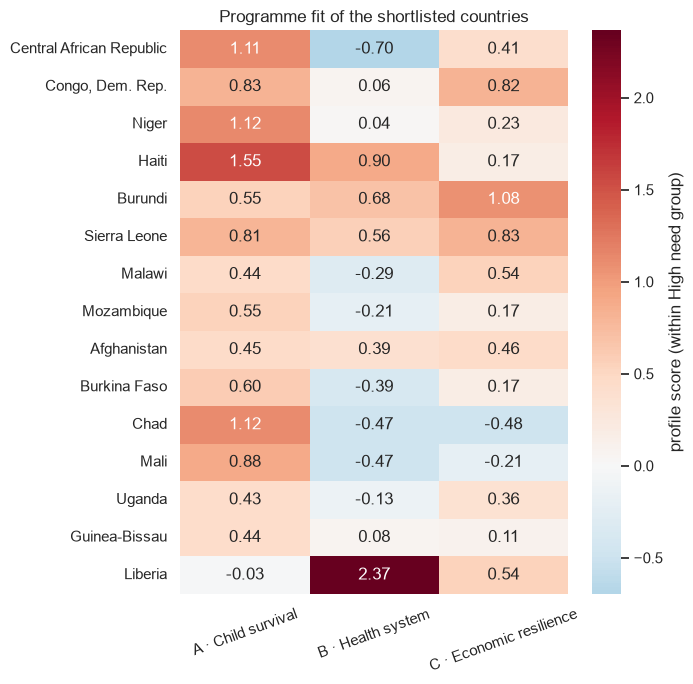

In [18]:
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(prog.loc[final.index, ["A", "B", "C"]], annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
            cbar_kws={"label": "profile score (within High need group)"})
ax.set_xticklabels([PROG_NAMES[p] for p in "ABC"], rotation=20)
ax.set_title("Programme fit of the shortlisted countries")
ax.set_ylabel("")
plt.tight_layout()

In [19]:
final["programme"].value_counts().rename("countries").to_frame()

,countries
programme,
A,10
C,4
B,1


## 5. Save results for the board notebook

In [20]:
out = clean[INDICATORS].copy()
out["type"] = cluster
out["need_index"] = need_index.round(1)
out["PC1"] = scores["PC1"].round(3)
out["PC2"] = scores["PC2"].round(3)
out["cluster_stability"] = cluster_stability.round(2)
out["top15_share"] = top15_share
out = out.join(prog[["programme", "margin"]])
out["shortlisted"] = out.index.isin(final.index)
out["reserve"] = out.index.isin(reserve.index)
out.to_csv("results/country_results.csv")
profile.to_csv("results/cluster_profiles.csv")
print("saved results/shortlist.csv, results/country_results.csv, results/cluster_profiles.csv")

saved results/shortlist.csv, results/country_results.csv, results/cluster_profiles.csv


## 6. Review of the findings

* **Need** is well defined by the data: PC1 explains 53 % of the variation and combines child mortality, fertility, life expectancy and income. Trade, health spending and inflation hardly matter for *need*, but they do matter for *which programme* fits.
* **Types:** four interpretable types. The core of the high-need type is stable across k, algorithms and bootstrap samples; only its upper edge moves.
* **Shortlist:** 7 countries are selected in ≥ 85 % of scenarios (high confidence). The other 8 are medium confidence. The most sensitive decision is **Liberia (63 %) vs. Guinea (58 %)** for the last place: Guinea has higher child mortality, Liberia much lower income. This is a value judgement for the board, not something the data can decide.
* **Data corrections did not drive the result:** Nigeria (need rank 24) and Myanmar (Emerging economies) are far from the shortlist either way.
* **Programme mix:** 10 × **A** (child survival), 4 × **C** (economic resilience), 1 × **B** (health system: Liberia, imports 93 % of GDP and health spending 12 % of GDP). Five assignments are close calls (DR Congo, Sierra Leone, Malawi, Afghanistan, Uganda); these need local expert input before the grant.
* **Data caveats that affect the decision:** Haiti's values reflect the 2010 earthquake; Nigeria's inflation and Myanmar's trade data had to be imputed; six crisis countries (e.g. Somalia, South Sudan, Ethiopia) are not in the data.
